# Responsible ML: Fairness, Interpretability, and Privacy

> Audit error differences across groups and communicate limitations without overclaiming.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Inspect overall and subgroup metrics.
- Explain why fairness is contextual and cannot be reduced to one number.
- Compute permutation importance on held-out data.
- Recognize privacy and governance risks.

Fairness depends on the harms and decisions involved, not only on a model's intent. Toolkits such as Fairlearn help measure and mitigate certain disparities, but stakeholder review and domain context remain essential. Reference: https://fairlearn.org/main/user_guide/index.html

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score

rng = np.random.default_rng(42)
X, y = make_classification(n_samples=1200, n_features=8, n_informative=5, random_state=42)
# Synthetic group label used only to demonstrate subgroup reporting (not a real protected attribute).
group = rng.choice(["Group A", "Group B"], size=len(y), p=[.6,.4])
X_train, X_test, y_train, y_test, group_train, group_test = train_test_split(X,y,group,test_size=.3,stratify=y,random_state=42)
model = RandomForestClassifier(n_estimators=60, min_samples_leaf=4, random_state=42).fit(X_train,y_train)
pred = model.predict(X_test)
rows=[]
for g in np.unique(group_test):
    m = group_test == g
    rows.append({"group":g, "n":int(m.sum()), "positive_rate":float(y_test[m].mean()), "selection_rate":float(pred[m].mean()), "precision":precision_score(y_test[m],pred[m],zero_division=0), "recall":recall_score(y_test[m],pred[m],zero_division=0)})
display(pd.DataFrame(rows).round(3))

,group,n,positive_rate,selection_rate,precision,recall
0,Group A,206,0.495,0.466,0.917,0.863
1,Group B,154,0.513,0.526,0.889,0.911


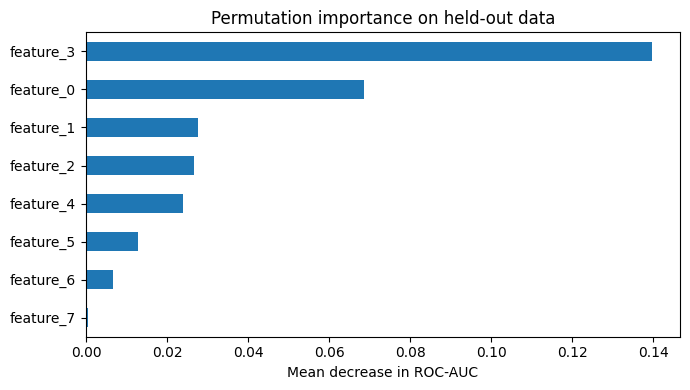

In [2]:
from sklearn.inspection import permutation_importance
result = permutation_importance(model, X_test, y_test, n_repeats=3, random_state=42, scoring="roc_auc")
importance = pd.Series(result.importances_mean, index=[f"feature_{i}" for i in range(X.shape[1])]).sort_values()
importance.plot(kind="barh", figsize=(7,4))
plt.title("Permutation importance on held-out data")
plt.xlabel("Mean decrease in ROC-AUC")
plt.tight_layout()

## Interpretability and fairness cautions
- Group metrics can be noisy when sample sizes are small; show counts and uncertainty.
- Different fairness criteria can conflict; the correct trade-off depends on context and law.
- Feature importance describes model behavior under a chosen evaluation setup, not causation.
- Removing a sensitive feature does not guarantee fairness; proxies may remain.
- Data minimization, access control, retention limits, consent/legal basis, and secure storage belong in the workflow—not as an afterthought.

## Practice
1. Add a confidence interval or bootstrap interval to a subgroup metric.
2. Give an example of a false positive that has different costs for two user groups.
3. Identify which parts of your dataset could be personal or sensitive information.